# Active subspaces of the global atmospheric selenium lifetime in SOCOL-AER

Stored data from

A. Feinberg, M. Maliki, A. Stenke, B. Sudret, T. Peter and L. H. E. Winkel, *Mapping the drivers of uncertainty
in atmospheric selenium deposition with global sensitivity analysis*, Atmospheric Chemistry and Physics
20(3):1363–1390, 2020. [doi:10.5194/acp-20-1363-2020](https://doi.org/10.5194/acp-20-1363-2020)

Aryeh Feinberg<sup>1,2,3</sup>, Moustapha Maliki<sup>4</sup>, Andrea Stenke<sup>1</sup>, Bruno Sudret<sup>4</sup>,
Thomas Peter<sup>1</sup>, Lenny H. E. Winkel<sup>2,3</sup>

<sup>1</sup> Department of Environmental Systems Science, Institute for Atmospheric and Climate Science, ETH Zurich,
Zurich, Switzerland; <sup>2</sup> Department of Environmental Systems Science, Institute of Biogeochemistry and
Pollutant Dynamics, ETH Zurich, Zurich, Switzerland; <sup>3</sup> Eawag, Swiss Federal Institute of Aquatic
Science and Technology, Dübendorf, Switzerland; <sup>4</sup> Chair of Risk, Safety and Uncertainty
Quantification, ETH Zurich, Zurich, Switzerland

Data: A. Feinberg et al., *Simulation data used for sensitivity analysis of atmospheric selenium in SOCOL-AER*,
ETH Research Collection, [doi:10.3929/ethz-b-000357105](https://doi.org/10.3929/ethz-b-000357105) (CC BY 4.0).

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import linprog
import active_subspaces as ac

SEED = 425                        # the only seed: every bootstrap and permutation below draws from it
t_start = time.perf_counter()

## Summary

Feinberg et al. built the first global atmospheric selenium model in the aerosol-chemistry-climate model
SOCOL-AER, ran it 400 times on a Latin hypercube over 34 uncertain Se-cycle inputs (rate constants, photolysis,
emission totals and speciation, aerosol uptake, a "dummy" aerosol), and deposited the annual-mean burden and
deposition fields; this notebook reduces them to the paper's scalar quantity of interest, the global Se lifetime
$\tau$ = burden / deposition, whose median over the runs (4.36 d) matches the paper's 4.4 d. With 400 runs and
no gradients, a linear fit (OLS) and a ridge-penalized quadratic surrogate give the same first direction
($|w_1^\top \hat w_1|$ = 0.986), led by the OCSe + OH rate constant $k_{13}$, which also leads the paper's
Sobol' ranking. A quadratic in two active variables predicts $\tau$ with leave-one-out $R^2$ 0.501 (everything
refitted in each fold), as well as the penalized quadratic in all 34 inputs (0.492) and better than one
variable (0.428), so the notebook chooses $n = 2$ (the same step appears for $1/\tau$ and $\log\tau$); about
half the variance of $\tau$ is not predicted out of sample, partly because 8 runs in its long upper tail hold
0.435 of its sum of squares, and $\lambda_2/\lambda_3$ (1.88) shows no gap after the second eigenvalue.

## Active subspaces in brief

For a function $f(\mathbf{z})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading
eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{z}$; a large gap after the $n$-th
eigenvalue means that $f$ varies mostly along the $n$ active variables $\mathbf{y} = \mathbf{W}_1^\top
\mathbf{z}$, which a sufficient summary plot of $f$ against $\mathbf{y}$ shows. Without gradients the matrix is
estimated from values: the linear least-squares estimator (OLS) fits $f \approx c + \mathbf{u}^\top \mathbf{z}$
and gives one direction $\mathbf{u}/\|\mathbf{u}\|$; a fitted quadratic surrogate gives gradients, and so a
full matrix, but a full quadratic in $m$ inputs has $(m+1)(m+2)/2$ coefficients and must be penalized when
there are fewer runs than that. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension
Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**SOCOL-AER** (paper, Sect. 2.1, p. 1365). SOCOL-AERv2 is a global chemistry-climate model: the general
circulation model ECHAM5 coupled to the chemistry model MEZON (89 gas-phase species, 239 gas-phase
reactions), with the sulfate aerosol microphysics of AER (40 size bins, 0.39 nm to 3.2 µm dry radius) and
interactive wet and dry deposition. The paper adds a selenium cycle (Sect. 2.2, pp. 1366–1368): seven gas-phase
tracers (OCSe, CSSe, CSe2, DMSe, H2Se, oxidized inorganic Se OX_Se_IN, oxidized organic Se OX_Se_OR), Se taken
up by the 40 sulfate bins, and a monodisperse "dummy" aerosol emitted in one latitude band to stand for the
missing non-sulfate aerosols. Each run (p. 1373): year-2000 boundary conditions, T42 resolution (64 × 128
Gaussian grid, about 2.8°) with 39 levels up to 0.01 hPa, chemistry decoupled from radiation (so all runs have
the same meteorology), 18 months from zero Se, the last 12 months analysed; about 14 h on 48 cores per run.

**Quantity of interest** (p. 1373). "The global Se lifetime is calculated as the total atmospheric Se burden
divided by total deposition." Here, from the deposited annual-mean fields (`convert_data.py`),

$$\tau = \frac{\sum_{s} \sum_{j,i} b_s(\phi_j,\lambda_i)\, A_j}{\sum_{d} \sum_{j,i} F_d(\phi_j,\lambda_i)\, A_j}
\cdot \frac{1}{86400\ \mathrm{s/d}}, \qquad A_j = a^2 w_j \frac{2\pi}{128},$$

with the 9 column burdens $b_s$ (kg Se m$^{-2}$: the five gas-phase precursors, OX_Se_IN, OX_Se_OR, Se on
sulfate and on dummy aerosol), the 4 wet and 4 dry deposition fluxes $F_d$ (kg Se m$^{-2}$ s$^{-1}$: of
OX_Se_IN, OX_Se_OR and the two aerosol phases), and the Gauss–Legendre weights $w_j$ of the 64 latitudes. The
cell areas and the use of annual means of the burden and the flux (not a monthly ratio) are this data set's
reading of the formula; $\tau$ does not depend on the Earth radius $a$.

**Inputs** (Table 3, p. 1370). 34 inputs: 12 measured and 5 estimated reaction rate constants (log-uniform
over bounds from Eqs. 1–2, pp. 1369–1371), 4 photolysis scale factors, 4 global emission totals, 5 speciation
fractions, the accommodation coefficient, and three dummy-aerosol parameters. Two of them are not ordinary
independent inputs:

- **emiss_aer** depends on r_aer: "the value of emission magnitude in our experiments depends lognormally on
  the particle radius ($r$), with mean $\mu = 2.54r + 19.0$ and standard deviation $\sigma = 2.88$"
  (Sect. 3.1.7, p. 1372). The paper does not say in which units or logarithm; the deposited files fix it (next
  section): $\ln(\mathrm{emiss\_aer}/\mathrm{kg\,yr^{-1}}) \sim N(19.0 + 2.54\, r_{aer}/\mathrm{µm},\ 2.88^2)$.
- **lat_aer** is one of 18 latitude bands of 10° (Table 3; 1 = 90–80° S, 18 = 80–90° N), a discrete input.

The table below is the code's list; for emiss_vol it prints Table 3's range, which the deposited design does
not use (see the design checks).

In [2]:
# The 34 inputs in the column order of se_training_inputs.csv: name, description, units, distribution,
# lower and upper bound (Table 3, p. 1370; emiss_aer: Sect. 3.1.7, p. 1372).
INPUTS = [
    ('k1', 'OCSe + O -> CO + OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 1.3e-12, 4.5e-10),
    ('k2', 'CSe2 + O -> OCSe + OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 2.6e-12, 7.8e-10),
    ('k3', 'CSe2 + O -> 2 OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 6.0e-12, 1.0e-9),
    ('k4', 'CSSe + O -> OCSe', 'cm3 molec-1 s-1', 'loguniform', 4.0e-13, 1.8e-10),
    ('k5', 'CSSe + O -> OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 1.0e-12, 3.8e-10),
    ('k6', 'DMSe + OH -> OX_Se_OR', 'cm3 molec-1 s-1', 'loguniform', 4.1e-12, 1.0e-9),
    ('k7', 'DMSe + NO3 -> OX_Se_OR', 'cm3 molec-1 s-1', 'loguniform', 7.0e-13, 2.8e-10),
    ('k8', 'DMSe + O3 -> OX_Se_OR', 'cm3 molec-1 s-1', 'loguniform', 7.8e-19, 5.9e-15),
    ('k9', 'DMSe + Cl -> OX_Se_OR', 'cm3 molec-1 s-1', 'loguniform', 3.8e-11, 1.0e-9),
    ('k10', 'H2Se + O -> OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 8.3e-14, 5.3e-11),
    ('k11', 'H2Se + Cl -> OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 4.6e-11, 1.0e-9),
    ('k12', 'H2Se + O3 -> OX_Se_IN', 'cm3 molec-1 s-1', 'loguniform', 4.4e-18, 2.3e-14),
    ('k13', 'OCSe + OH -> OX_Se_IN (estimated)', 'cm3 molec-1 s-1', 'loguniform', 2.6e-14, 1.3e-11),
    ('k14', 'CSe2 + OH -> OCSe + OX_Se_IN (estimated)', 'cm3 molec-1 s-1', 'loguniform', 7.0e-12, 1.0e-9),
    ('k15', 'CSSe + OH -> OX_Se_IN (estimated)', 'cm3 molec-1 s-1', 'loguniform', 9.8e-13, 4.5e-10),
    ('k16', 'CSSe + OH -> OCSe (estimated)', 'cm3 molec-1 s-1', 'loguniform', 4.2e-13, 1.9e-10),
    ('k17', 'H2Se + OH -> OX_Se_IN (estimated)', 'cm3 molec-1 s-1', 'loguniform', 3.3e-12, 1.0e-9),
    ('fk18', 'photolysis scaling, OCSe', '1', 'uniform', 0.0, 2.0),
    ('fk19', 'photolysis scaling, CSe2', '1', 'uniform', 0.0, 2.0),
    ('fk20', 'photolysis scaling, CSSe', '1', 'uniform', 0.0, 2.0),
    ('fk21', 'photolysis scaling, H2Se', '1', 'uniform', 0.0, 2.0),
    ('emiss_mar', 'marine biogenic emissions', 'Gg Se/yr', 'loguniform', 0.4, 35.0),
    ('emiss_terr', 'terrestrial biogenic emissions', 'Gg Se/yr', 'uniform', 0.15, 5.25),
    ('emiss_ant', 'anthropogenic emissions', 'Gg Se/yr', 'uniform', 3.0, 9.6),
    ('emiss_vol', 'volcanic emissions', 'Gg Se/yr', 'loguniform', 0.076, 49.1),
    ('pOCSe_ant', 'OCSe fraction of anthropogenic emissions', '%', 'uniform', 0.0, 6.0),
    ('pCSe2_ant', 'CSe2 fraction of anthropogenic emissions', '%', 'uniform', 0.0, 6.0),
    ('pCSSe_ant', 'CSSe fraction of anthropogenic emissions', '%', 'uniform', 0.0, 6.0),
    ('pH2Se_ant', 'H2Se fraction of anthropogenic emissions', '%', 'uniform', 0.0, 6.0),
    ('pH2Se_vol', 'H2Se fraction of volcanic emissions', '%', 'uniform', 0.0, 13.0),
    ('acc_coeff', 'accommodation coefficient of oxidized Se', '1', 'uniform', 0.02, 1.0),
    ('r_aer', 'dummy aerosol radius', 'um', 'loguniform', 0.01, 3.0),
    ('emiss_aer', 'dummy aerosol emission', 'kg/yr', 'lognormal given r_aer', np.nan, np.nan),
    ('lat_aer', 'dummy aerosol latitude band (1 = 90-80S, 18 = 80-90N)', 'band', 'discrete uniform', 1, 18),
]
NAMES = [r[0] for r in INPUTS]
m = len(INPUTS)
AER_MU = (19.0, 2.54)      # ln(emiss_aer / (kg/yr)) ~ Normal(19.0 + 2.54 r_aer / um, 2.88^2), p. 1372
AER_SIGMA = 2.88
print(f'{"name":11s} {"distribution":22s} {"lower":>9s} {"upper":>9s}  units, description')
for n, d, u, dist, lo, hi in INPUTS:
    print(f'{n:11s} {dist:22s} {lo:9.3g} {hi:9.3g}  {u}, {d}')

name        distribution               lower     upper  units, description
k1          loguniform               1.3e-12   4.5e-10  cm3 molec-1 s-1, OCSe + O -> CO + OX_Se_IN
k2          loguniform               2.6e-12   7.8e-10  cm3 molec-1 s-1, CSe2 + O -> OCSe + OX_Se_IN
k3          loguniform                 6e-12     1e-09  cm3 molec-1 s-1, CSe2 + O -> 2 OX_Se_IN
k4          loguniform                 4e-13   1.8e-10  cm3 molec-1 s-1, CSSe + O -> OCSe
k5          loguniform                 1e-12   3.8e-10  cm3 molec-1 s-1, CSSe + O -> OX_Se_IN
k6          loguniform               4.1e-12     1e-09  cm3 molec-1 s-1, DMSe + OH -> OX_Se_OR
k7          loguniform                 7e-13   2.8e-10  cm3 molec-1 s-1, DMSe + NO3 -> OX_Se_OR
k8          loguniform               7.8e-19   5.9e-15  cm3 molec-1 s-1, DMSe + O3 -> OX_Se_OR
k9          loguniform               3.8e-11     1e-09  cm3 molec-1 s-1, DMSe + Cl -> OX_Se_OR
k10         loguniform               8.3e-14   5.3e-11  cm3 mole

## Load the data

Four CSV files, written by `convert_data.py` from the ETH Research Collection record 10.3929/ethz-b-000357105:
the inputs of the 400 training runs in physical units and in the authors' transformed units (both copied
character for character), and the global totals of the annual-mean fields of the 400 training and 50
validation runs with $\tau$. The record offered no input values for the 50 validation runs, so they serve only
as a second sample of $\tau$.

In [3]:
def read(path):
    """Values and column names (units in brackets stripped) of one of this data set's CSVs."""
    with open(path, encoding='utf-8') as fh:
        fh.readline()
        cols = [c.split(' [')[0] for c in fh.readline()[2:].strip().split(',')]
    return np.loadtxt(path, delimiter=',', ndmin=2), cols


XI, ci = read('se_training_inputs.csv')                   # 400 x (2 + 34), physical units
XT, ct = read('se_training_inputs_transformed.csv')       # 400 x (2 + 34), the authors' transformed units
FO, co = read('se_training_outputs.csv')                  # 400 x (1 + 21): global totals and tau
FV, cv = read('se_validation_outputs.csv')                # 50 x (1 + 21); no inputs deposited for these
assert ci[2:] == NAMES and ct[2:] == NAMES and co == cv
X, T = XI[:, 2:], XT[:, 2:]
assert np.all(XI[:, 0] == FO[:, 0]) and np.all(XI[:, 0] == np.arange(1, 401))
out = {c: FO[:, j] for j, c in enumerate(co)}
val = {c: FV[:, j] for j, c in enumerate(cv)}
tau, tau_v = out['tau'], val['tau']
M = len(tau)
print('training inputs', X.shape, ' transformed', T.shape, ' outputs', FO.shape, ' validation outputs', FV.shape)
print(f'experiment numbers {int(XI[0, 1])}-{int(XI[-1, 1])}; tau recomputed from the totals, largest '
      f'relative difference {np.max(np.abs(out["burden_total"] / (out["wet_total"] + out["dry_total"]) / 86400 / tau - 1)):.1e}')

training inputs (400, 34)  transformed (400, 34)  outputs (400, 22)  validation outputs (50, 22)
experiment numbers 20001-20516; tau recomputed from the totals, largest relative difference 0.0e+00


### Design, and checks of the inputs

The paper's design (pp. 1372–1373): a Latin hypercube of $N$ = 400 points, "each parameter range is divided
into $N$ equally probable subintervals". The cell compares the two deposited input files, recovers the law of
emiss_aer, and counts the occupied strata.

In [4]:
ilog = [i for i, r in enumerate(INPUTS) if r[3] == 'loguniform']
iuni = [i for i, r in enumerate(INPUTS) if r[3] == 'uniform']
ir, ie, il = NAMES.index('r_aer'), NAMES.index('emiss_aer'), NAMES.index('lat_aer')
print('authors\' transformed units against the physical values:')
print(f'  log-uniform inputs: largest |log10(x) - t| = {np.abs(np.log10(X[:, ilog]) - T[:, ilog]).max():.1e} '
      f'(k1-k17: {np.abs(np.log10(X[:, :17]) - T[:, :17]).max():.1e}; the others: '
      f'{np.abs(np.log10(X[:, [21, 24, 31]]) - T[:, [21, 24, 31]]).max():.1e})')
print(f'  uniform inputs: largest |x - t| = {np.abs(X[:, iuni] - T[:, iuni]).max():.1e}')
z_aer = (np.log(X[:, ie]) - AER_MU[0] - AER_MU[1] * X[:, ir]) / AER_SIGMA
print(f'  emiss_aer: largest |Phi((ln e - 19.0 - 2.54 r) / 2.88) - t| = {np.abs(stats.norm.cdf(z_aer) - T[:, ie]).max():.1e}')
cf, *_ = np.linalg.lstsq(np.column_stack([np.ones(M), X[:, ir], stats.norm.ppf(T[:, ie])]), np.log(X[:, ie]), rcond=None)
print(f'    least squares of ln e on [1, r, Phi^-1(t)]: {cf[0]:.4f} + {cf[1]:.4f} r + {cf[2]:.4f} z')
print(f'  lat_aer: band = ceil(t) in all rows: {bool(np.all(np.ceil(T[:, il]) == X[:, il]))}; '
      f'rows per band {np.bincount(X[:, il].astype(int))[1:].min()}-{np.bincount(X[:, il].astype(int))[1:].max()}')


def cdf(i, x, xr=None):
    """CDF of input i under the Table 3 law, at the values x (xr: r_aer, for the conditional law of emiss_aer)."""
    n, _, _, dist, lo, hi = INPUTS[i]
    if dist == 'loguniform':
        return (np.log10(x) - np.log10(lo)) / (np.log10(hi) - np.log10(lo))
    if dist == 'uniform':
        return (x - lo) / (hi - lo)
    if n == 'emiss_aer':
        return stats.norm.cdf((np.log(x) - AER_MU[0] - AER_MU[1] * xr) / AER_SIGMA)
    return (x - 0.5) / 18.0                         # lat_aer: the band midpoints of [0, 18]


def cdf_t(i, t):
    """CDF of input i at the authors' transformed value t (full precision; lat_aer: its latent value)."""
    n, _, _, dist, lo, hi = INPUTS[i]
    if dist == 'loguniform':
        return (t - np.log10(lo)) / (np.log10(hi) - np.log10(lo))
    if dist == 'uniform':
        return (t - lo) / (hi - lo)
    return t if n == 'emiss_aer' else t / 18.0


UT = np.column_stack([cdf_t(i, T[:, i]) for i in range(m)])
print('\nLatin hypercube check: occupied strata of 400 equal-probability strata (Table 3 laws, transformed values)')
occ = np.array([len(np.unique(np.floor(UT[:, i] * M).clip(0, M - 1))) for i in range(m)])
outside = ((UT < 0) | (UT > 1)).sum(axis=0)
for i in range(m):
    if occ[i] < M or outside[i]:
        print(f'  {NAMES[i]:10s} occupied {occ[i]:3d}, outside the Table 3 range {outside[i]:3d}, '
              f'sample range [{X[:, i].min():.4g}, {X[:, i].max():.4g}]')
print(f'  each of the other {np.sum((occ == M) & (outside == 0))} inputs: 400 of 400 strata, none outside')
iv = NAMES.index('emiss_vol')
# Which log-uniform ranges [a, b] make the emiss_vol column a Latin hypercube (one run in each of the 400
# strata)? With s_k the sorted log10 values: log a + k w <= s_k <= log a + (k + 1) w, w = (log b - log a) / 400,
# linear in (log a, log b); the extreme feasible bounds come from four linear programs.
s = np.sort(T[:, iv])
kk = np.arange(M)
A_lp = np.vstack([np.column_stack([1 - kk / M, kk / M]), -np.column_stack([1 - (kk + 1) / M, (kk + 1) / M])])
b_lp = np.concatenate([s, -s])
ext = [linprog(c, A_ub=A_lp, b_ub=b_lp, bounds=[(None, None)] * 2).x for c in ([1, 0], [-1, 0], [0, 1], [0, -1])]
va_lo, va_hi = 10**ext[0][0], 10**ext[1][0]
vb_lo, vb_hi = 10**ext[2][1], 10**ext[3][1]
print(f'emiss_vol: every log-uniform range that fills all 400 strata has its lower end in [{va_lo:.6f}, {va_hi:.6f}] '
      f'and its upper end in [{vb_lo:.4f}, {vb_hi:.4f}] (column units)')
for a_, b_ in ((0.06, 39.0), (0.076, 49.1)):
    u_ = (s - np.log10(a_)) / (np.log10(b_) - np.log10(a_))
    print(f'  on [{a_}, {b_}]: {len(np.unique(np.floor(u_ * M).clip(0, M - 1)))} of 400 strata occupied, '
          f'{np.sum((u_ < 0) | (u_ > 1))} runs outside')

authors' transformed units against the physical values:
  log-uniform inputs: largest |log10(x) - t| = 2.1e-03 (k1-k17: 2.1e-03; the others: 2.2e-14)
  uniform inputs: largest |x - t| = 0.0e+00
  emiss_aer: largest |Phi((ln e - 19.0 - 2.54 r) / 2.88) - t| = 1.1e-03
    least squares of ln e on [1, r, Phi^-1(t)]: 18.9923 + 2.5446 r + 2.8816 z
  lat_aer: band = ceil(t) in all rows: True; rows per band 21-23

Latin hypercube check: occupied strata of 400 equal-probability strata (Table 3 laws, transformed values)
  k13        occupied 364, outside the Table 3 range   0, sample range [2.63e-14, 1.29e-11]
  k14        occupied 364, outside the Table 3 range   0, sample range [7.04e-12, 9.92e-10]
  k15        occupied 373, outside the Table 3 range   0, sample range [9.87e-13, 4.44e-10]
  k16        occupied 369, outside the Table 3 range   0, sample range [4.26e-13, 1.87e-10]
  k17        occupied 363, outside the Table 3 range   0, sample range [3.31e-12, 9.88e-10]
  emiss_vol  occupied 29

**The transformed file is the authors' uniformizing map.** It holds $\log_{10}$ of the 20 log-uniform inputs,
the 12 uniform inputs unchanged, for emiss_aer the conditional CDF value $u = \Phi((\ln e - 19.0 - 2.54 r)/2.88)$
(to 1.1e-03; a least-squares fit gives 18.9923 + 2.5446 r + 2.8816 z, so the printed constants are rounded),
and for lat_aer a latent value whose ceiling is the band. The physical file writes $k_1$–$k_{17}$ with three
significant digits (hence the 2.1e-03 difference in $\log_{10}$); everything else agrees to rounding (of order 1e-14).

**The strata.** 28 inputs, emiss_aer's $u$ and the latent lat_aer included, fill each of the 400 strata once:
a Latin hypercube. Two groups do not. The five estimated rate constants $k_{13}$–$k_{17}$ lie inside their
Table 3 ranges but occupy only 363–373 strata, so they were not stratified on these ranges (the paper does not
say why; their bounds come from a regression interval, Eq. 2). And **emiss_vol is not on Table 3's range**: on
[0.076, 49.1] it occupies only 293 strata and 15 runs lie below 0.076. The log-uniform ranges on which the column
is a Latin hypercube have lower ends 0.059997–0.060011 and upper ends 38.9990–39.0052: the design range is
[0.06, 39] in the column's units, on which all 400 strata are occupied and no run is outside. The mass balance
below explains the factor between the two ranges.

### Mass balance

"All 400 training runs showed very good Se mass conservation: total annual Se deposition fluxes were 98 %–102 %
of total emission fluxes" (p. 1376). The four emission totals are scaling factors of maps normalized to
1 Gg Se/yr (p. 1371), so deposition should equal their sum. Here a year is 365.25 d (this data set's choice;
$\tau$ does not use it).

In [5]:
YEAR = 365.25 * 86400.0          # s per year used for Gg/yr (this data set's choice; tau does not use it)
dep = (out['wet_total'] + out['dry_total']) * YEAR / 1e6            # Gg Se/yr
E4 = X[:, [NAMES.index(n) for n in ('emiss_mar', 'emiss_terr', 'emiss_ant', 'emiss_vol')]]
r0 = dep / E4.sum(axis=1)
print(f'total deposition {dep.min():.2f}-{dep.max():.2f} Gg Se/yr; burden {out["burden_total"].min() / 1e6:.3f}-'
      f'{out["burden_total"].max() / 1e6:.3f} Gg Se; wet share of deposition {np.median(out["wet_total"] / (out["wet_total"] + out["dry_total"])):.3f} '
      f'(median; range {np.min(out["wet_total"] / (out["wet_total"] + out["dry_total"])):.3f}-{np.max(out["wet_total"] / (out["wet_total"] + out["dry_total"])):.3f})')
print(f'deposition / (emiss_mar + emiss_terr + emiss_ant + emiss_vol): {r0.min():.3f}-{r0.max():.3f} (median {np.median(r0):.3f})')
cm, *_ = np.linalg.lstsq(E4, dep, rcond=None)
res = dep - E4 @ cm
print('least squares dep = c_mar emiss_mar + c_terr emiss_terr + c_ant emiss_ant + c_vol emiss_vol: '
      + ', '.join(f'{c:.4f}' for c in cm) + f'; residual sd {res.std():.3f} Gg/yr (sd of dep {dep.std():.2f})')
r1 = dep / (E4[:, :3].sum(axis=1) + cm[3] * E4[:, 3])
print(f'deposition / (mar + terr + ant + {cm[3]:.3f} vol): {r1.min():.3f}-{r1.max():.3f}')
print(f'Table 3 volcanic bounds / design-range bounds: {0.076 / 0.06:.3f} (lower), {49.1 / 39.0:.3f} (upper)')
SE_S = (6e-6, 3.9e-3)              # volcanic Se/S mass ratios, White Island and Merapi (p. 1371)
print('Se/S ratio bounds x 10 Tg S/yr = ' + ', '.join(f'{r * 10e3:.4g}' for r in SE_S) + ' Gg Se/yr; x 12.6 Tg S/yr '
      '(the paper\'s volcanic S, p. 1371) = ' + ', '.join(f'{r * 12.6e3:.4g}' for r in SE_S) + f' Gg Se/yr; 12.6 / 10 = {12.6 / 10:.2f}')

total deposition 5.65-85.83 Gg Se/yr; burden 0.048-1.076 Gg Se; wet share of deposition 0.771 (median; range 0.696-0.889)
deposition / (emiss_mar + emiss_terr + emiss_ant + emiss_vol): 0.988-1.233 (median 1.036)
least squares dep = c_mar emiss_mar + c_terr emiss_terr + c_ant emiss_ant + c_vol emiss_vol: 0.9839, 1.0253, 1.0219, 1.2693; residual sd 0.024 Gg/yr (sd of dep 14.49)
deposition / (mar + terr + ant + 1.269 vol): 0.987-1.023
Table 3 volcanic bounds / design-range bounds: 1.267 (lower), 1.259 (upper)
Se/S ratio bounds x 10 Tg S/yr = 0.06, 39 Gg Se/yr; x 12.6 Tg S/yr (the paper's volcanic S, p. 1371) = 0.0756, 49.14 Gg Se/yr; 12.6 / 10 = 1.26


With the deposited columns, deposition is 0.988–1.233 of the summed emissions, not 98–102 %. A regression
of deposition on the four columns explains it: the marine, terrestrial and anthropogenic coefficients are
0.9839, 1.0253 and 1.0219, the volcanic one 1.2693 (residual sd 0.024 Gg/yr against an sd of 14.49), and with
that factor deposition is 0.987–1.023 of emissions, close to the paper's range. The ratios of Table 3's
volcanic bounds to the design bounds are 1.267 and 1.259. So the deposited emiss_vol column is the scaling of
a volcanic map that emits about 1.269 Gg Se/yr per unit, and Table 3's range is the emitted Se. This is an
inference from the data; the paper says every map was normalized to 1 Gg Se/yr. A candidate cause, also this
data set's inference and not stated in the paper: the design bounds equal the paper's volcanic Se/S ratio bounds,
6e-6 and 3.9e-3 (p. 1371), times 10 Tg S/yr (0.06 and 39 Gg Se/yr), whereas Table 3's bounds are the same
ratios times the 12.6 Tg S/yr the paper uses (0.0756 and 49.14); 12.6/10 = 1.26, close to the volcanic
coefficient 1.269. The notebook keeps the column as deposited and scales it on its design range, [0.06, 39] in
column units (log-uniform); since the factor is nearly the same at both ends, this is the same normalized
coordinate as Table 3's range of emitted Se.
Wet deposition is a median 0.771 of the total (0.696–0.889).

### The lifetime over the runs

The paper's Fig. 4 (p. 1377) is a histogram of 40,000 samples of its surrogate (the ratio of a burden PCE and
a deposition PCE): "a median of 4.4 d (days), 2nd percentile value of 2.9 d, and 98th percentile value of
6.4 d". The 400 runs are a Latin hypercube of the same input law, so their quantiles estimate the same
quantities directly (with the emiss_vol and $k_{13}$–$k_{17}$ caveats above).

In [6]:
pct = [2, 50, 98]
print('tau, training runs:   2/50/98 % = ' + ' / '.join(f'{v:.2f}' for v in np.percentile(tau, pct))
      + f' d; min {tau.min():.2f}, max {tau.max():.2f}, mean {tau.mean():.2f} d')
print('tau, validation runs: 2/50/98 % = ' + ' / '.join(f'{v:.2f}' for v in np.percentile(tau_v, pct))
      + f' d; min {tau_v.min():.2f}, max {tau_v.max():.2f}')
ks = stats.ks_2samp(tau, tau_v)
print(f'two-sample Kolmogorov-Smirnov, training vs validation: D = {ks.statistic:.3f}, p = {ks.pvalue:.2f}')
bs = np.random.default_rng(SEED).choice(tau, size=(2000, M))
q = np.percentile(bs, pct, axis=1)
for p, qq in zip(pct, q):
    print(f'  bootstrap 95% interval of the {p:2d} % quantile of the training runs: '
          f'[{np.percentile(qq, 2.5):.2f}, {np.percentile(qq, 97.5):.2f}] d')
print(f'runs with tau > 6.4 d (the paper\'s 98th percentile): {np.sum(tau > 6.4)} of {M}; tau < 2.9 d: {np.sum(tau < 2.9)}')

tau, training runs:   2/50/98 % = 3.52 / 4.36 / 6.38 d; min 3.11, max 10.07, mean 4.48 d
tau, validation runs: 2/50/98 % = 3.52 / 4.28 / 6.42 d; min 3.34, max 6.67
two-sample Kolmogorov-Smirnov, training vs validation: D = 0.125, p = 0.46
  bootstrap 95% interval of the  2 % quantile of the training runs: [3.50, 3.63] d
  bootstrap 95% interval of the 50 % quantile of the training runs: [4.30, 4.42] d
  bootstrap 95% interval of the 98 % quantile of the training runs: [5.98, 6.97] d
runs with tau > 6.4 d (the paper's 98th percentile): 8 of 400; tau < 2.9 d: 0


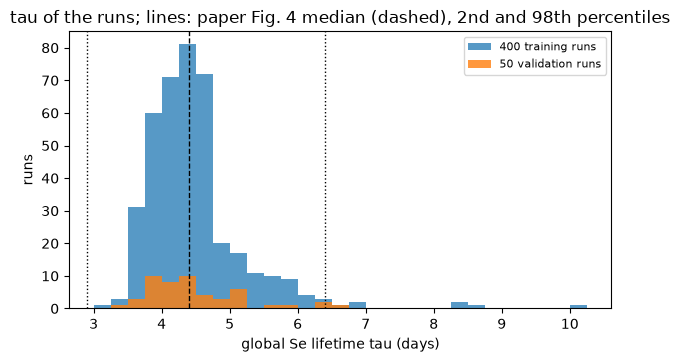

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(3.0, 10.25, 30)
ax.hist(tau, bins=bins, color='C0', alpha=0.75, label=f'{M} training runs')
ax.hist(tau_v, bins=bins, color='C1', alpha=0.8, label=f'{len(tau_v)} validation runs')
for v, ls in zip((2.9, 4.4, 6.4), (':', '--', ':')):
    ax.axvline(v, c='k', ls=ls, lw=1)
ax.set_xlabel('global Se lifetime tau (days)')
ax.set_ylabel('runs')
ax.set_title('tau of the runs; lines: paper Fig. 4 median (dashed), 2nd and 98th percentiles')
ax.legend(fontsize=8)
plt.close(fig)
fig

The median of the runs, 4.36 d (bootstrap 95 % [4.30, 4.42]), and the 98th percentile, 6.38 d
([5.98, 6.97]), agree with Fig. 4. **The 2nd percentile does not**: 3.52 d ([3.50, 3.63]) against the paper's
2.9 d, and no run has $\tau$ below 2.9 d (the minimum is 3.11 d). The surrogate's lower tail is therefore
longer than the model's; a ratio of two surrogates with LOO errors 0.02 and 1e-6 (p. 1376) can extrapolate
below the runs. The validation runs are consistent with the training runs (a Kolmogorov–Smirnov test does not
reject equal distributions, p = 0.46; median 4.28 d, 2nd–98th percentiles 3.52–6.42 d). Eight runs exceed 6.4 d, up to 10.07 d.

## Estimate the active subspace

**Coordinates.** Each input is mapped to $[-1, 1]$ through its own CDF: $z = 2F(x) - 1$, with Table 3's laws
(log-uniform: affine in $\log_{10} x$; uniform: affine in $x$), emiss_vol on its design range, emiss_aer
through its conditional CDF given r_aer (a Rosenblatt transform, which makes it independent of r_aer), and
lat_aer at the band midpoints, $z = (2\,\mathrm{band} - 19)/18$. In these coordinates the 34 inputs are
independent and uniform on $[-1, 1]$ (lat_aer discrete uniform on 18 points), the density of the analysis is
the paper's input law, and the space is `ac.Uniform(-1, 1)` with $Z$ passed as data. A gradient in $z$ is a
change of $\tau$ per unit of probability, not per physical unit. $Z$ is built from the physical values; built
from the authors' full-precision transformed values it differs by at most 2.9e-03, and the OLS direction does
not change (inner product 1.000000).

**Estimators.** There are no gradients, and $M$ = 400 runs: a full quadratic in $m$ = 34 inputs has 630
coefficients, more than the runs, so the least-squares quadratic estimator (QPHD) cannot be used. The notebook uses (1) OLS, which gives one
direction; (2) a ridge-penalized quadratic (linear part unpenalized, the 595 second-order terms penalized,
penalty chosen by exact leave-one-out error), whose gradients give a full matrix $\mathbf{C}$; and (3) sliced
inverse regression (SIR) as a check that uses neither a linear nor a quadratic model. v1 warns that OLS and
SIR need a linearity condition that uniform inputs satisfy only in special cases; they are used here as
estimates of the best linear direction and as a check.

In [8]:
def to_unit(Xp):
    """Physical inputs -> [-1, 1]^34: each input through its CDF (emiss_aer: given r_aer; lat_aer: band midpoints)."""
    Up = np.column_stack([cdf(i, Xp[:, i], Xp[:, ir]) for i in range(m)])
    return 2.0 * Up - 1.0


VOL_DESIGN = (0.06, 39.0)        # emiss_vol column range of the design: the Latin hypercube range found above
INPUTS[iv] = INPUTS[iv][:4] + VOL_DESIGN
Z = to_unit(X)
ZT = 2.0 * np.column_stack([cdf_t(i, T[:, i]) for i in range(m)]) - 1.0
ZT[:, il] = Z[:, il]                              # lat_aer: band midpoints, not the latent value
print(f'Z in [{Z.min():.4f}, {Z.max():.4f}]; largest difference from Z computed from the transformed file: '
      f'{np.abs(Z - ZT).max():.1e}')
space = ac.Uniform(-np.ones(m), np.ones(m), names=NAMES)
print(f'M = {M} runs; a full quadratic in m = {m} inputs has {(m + 1) * (m + 2) // 2} coefficients, '
      f'{m * (m + 1) // 2} of them second-order')

Z in [-1.0000, 1.0000]; largest difference from Z computed from the transformed file: 2.9e-03
M = 400 runs; a full quadratic in m = 34 inputs has 630 coefficients, 595 of them second-order


In [9]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    sub = ac.active_subspace(space=space, X=Z, f=tau, estimator='ols', n=1, nboot=500, bootstrap_vectors=1,
                             rng=SEED, qoi='tau')
print('v1 warnings:', sorted({f'{w.category.__name__}: {str(w.message)[:100]}' for w in caught}))
A1 = np.column_stack([np.ones(M), Z])
Q1, _ = np.linalg.qr(A1)
h1 = np.sum(Q1**2, axis=1)
coef1, *_ = np.linalg.lstsq(A1, tau, rcond=None)
res1 = tau - A1 @ coef1
r2_lin = 1 - np.sum(res1**2) / np.sum((tau - tau.mean())**2)
loo_lin = 1 - np.sum((res1 / (1 - h1))**2) / np.sum((tau - tau.mean())**2)
lam1 = sub.eigenvalues[0]
bl = sub.bootstrap_eigenvalues[:, 0]
print(f'linear fit of tau on the 34 normalized inputs: R^2 = {r2_lin:.3f}, LOO R^2 = {loo_lin:.3f}')
print(f'OLS lambda1 = ||u||^2 = {lam1:.4f} d^2 (bootstrap 2.5-97.5 %: [{np.percentile(bl, 2.5):.4f}, '
      f'{np.percentile(bl, 97.5):.4f}]); bootstrap mean distance of w1: {sub.bootstrap_distances[:, 0].mean():.3f}')
rng = np.random.default_rng(SEED)
null_l1, null_r2 = [], []
for _ in range(500):
    fp = rng.permutation(tau)
    c, *_ = np.linalg.lstsq(A1, fp, rcond=None)
    null_l1.append(np.sum(c[1:]**2))
    null_r2.append(1 - np.sum((fp - A1 @ c)**2) / np.sum((fp - fp.mean())**2))
cT, *_ = np.linalg.lstsq(np.column_stack([np.ones(M), ZT]), tau, rcond=None)
print(f'w1 from the transformed-file coordinates: |w1^T w1T| = {abs(cT[1:] @ sub.W[:, 0]) / np.linalg.norm(cT[1:]):.6f}')
print(f'permuted tau (500 permutations): lambda1 95 % quantile {np.percentile(null_l1, 95):.4f} '
      f'(max {np.max(null_l1):.4f}; observed / quantile {lam1 / np.percentile(null_l1, 95):.1f}); '
      f'in-sample R^2 95 % quantile {np.percentile(null_r2, 95):.3f}')

v1 warnings: ["ValidityWarning: outside the method's assumptions; estimator 'ols' on a uniform space: needs the linearity condition,"]
linear fit of tau on the 34 normalized inputs: R^2 = 0.470, LOO R^2 = 0.360
OLS lambda1 = ||u||^2 = 0.8293 d^2 (bootstrap 2.5-97.5 %: [0.6421, 1.3014]); bootstrap mean distance of w1: 0.302
w1 from the transformed-file coordinates: |w1^T w1T| = 1.000000
permuted tau (500 permutations): lambda1 95 % quantile 0.2273 (max 0.3014; observed / quantile 3.6); in-sample R^2 95 % quantile 0.119


A linear function of the 34 inputs explains $R^2$ = 0.470 of the variance of $\tau$ in sample and 0.360 out
of sample (LOO); permuted $\tau$ reaches an in-sample $R^2$ of 0.119 (95 % quantile), so the linear trend is
real but weak. OLS's one eigenvalue is $\lambda_1 = \|\mathbf{u}\|^2$ = 0.8293 d² (bootstrap
[0.6421, 1.3014]), 3.6 times the 95 % permutation quantile 0.2273, and the bootstrap mean distance of $w_1$ is
0.302.

In [10]:
# Ridge-penalized quadratic in the 34 normalized inputs: the linear part unpenalized, the 595 squares and
# products penalized (after projecting out the linear part). Its gradients at the 400 points give the
# active-subspace matrix C = (1/M) sum_i grad q(z_i) grad q(z_i)^T.
JU, KU = np.triu_indices(m)
LAMS = np.logspace(-2, 5, 57)                  # penalties searched by exact leave-one-out error


def quad_prepare(Zs):
    A = np.column_stack([np.ones(len(Zs)), Zs])
    QA, _ = np.linalg.qr(A)
    B = Zs[:, JU] * Zs[:, KU]
    U_, s_, Vt_ = np.linalg.svd(B - QA @ (QA.T @ B), full_matrices=False)
    return dict(Z=Zs, A=A, QA=QA, hA=np.sum(QA**2, axis=1), B=B, U=U_, s=s_, Vt=Vt_)


def quad_fit(P, f, lam):
    """LOO R^2, gradients at P's points, and eigenpairs of the gradient matrix, at penalty lam."""
    d = P['s']**2 / (P['s']**2 + lam)
    r = f - P['QA'] @ (P['QA'].T @ f) - P['U'] @ (d * (P['U'].T @ f))
    h = P['hA'] + (P['U']**2) @ d
    loo = 1 - np.sum((r / (1 - h))**2) / np.sum((f - f.mean())**2)
    cq = P['Vt'].T @ ((P['s'] / (P['s']**2 + lam)) * (P['U'].T @ f))
    ca, *_ = np.linalg.lstsq(P['A'], f - P['B'] @ cq, rcond=None)
    H = np.zeros((m, m))
    H[JU, KU] = cq
    H = H + H.T                                # Hessian (the diagonal counted twice: d(c z^2)/dz = 2 c z)
    grads = ca[1:][None, :] + P['Z'] @ H
    ev, W = np.linalg.eigh(grads.T @ grads / len(f))
    return loo, grads, ev[::-1], W[:, ::-1], (ca, H)


PQ = quad_prepare(Z)
loos = np.array([quad_fit(PQ, tau, L)[0] for L in LAMS])
lam_q = LAMS[np.argmax(loos)]
loo_q, Gq, evq, Wq, coef_q = quad_fit(PQ, tau, lam_q)
Wq[:, 0] *= np.sign(Wq[:, 0] @ sub.W[:, 0])            # tau increases along w1 (as for OLS)
Wq[:, 1] *= np.sign(Wq[np.argmax(np.abs(Wq[:, 1])), 1])  # w2: largest-magnitude entry positive
equiv = [L for L, lv in zip(LAMS, loos) if lv >= loos.max() - 0.005]
rat = np.array([(lambda e: (e[0] / e[1], e[1] / e[2], e[2] / e[3]))(quad_fit(PQ, tau, L)[2]) for L in equiv])
print(f'penalized quadratic: LOO R^2 {loo_q:.3f} at penalty {lam_q:.3g} (linear fit {loo_lin:.3f}; '
      f'over the grid {loos.min():.3f}-{loos.max():.3f})')
print('  eigenvalues 1-5 of its gradient matrix (d^2): ' + ' '.join(f'{v:.4f}' for v in evq[:5]))
print(f'  lambda1/lambda2 = {evq[0] / evq[1]:.2f}, lambda2/lambda3 = {evq[1] / evq[2]:.2f}, '
      f'lambda3/lambda4 = {evq[2] / evq[3]:.2f}; share of trace(C) outside the first two: '
      f'{evq[2:].sum() / evq.sum():.3f}')
print(f'  over the penalties {equiv[0]:.3g}-{equiv[-1]:.3g} (LOO R^2 within 0.005 of the best): lambda1/lambda2 '
      f'{rat[:, 0].min():.2f}-{rat[:, 0].max():.2f}, lambda2/lambda3 {rat[:, 1].min():.2f}-{rat[:, 1].max():.2f}, '
      f'lambda3/lambda4 {rat[:, 2].min():.2f}-{rat[:, 2].max():.2f}')
near = [(L, lv) for L, lv in zip(LAMS, loos) if lv >= loos.max() - 0.05]
rat_wide = np.array([(lambda e: e[0] / e[1])(quad_fit(PQ, tau, L)[2]) for L, _ in near])
print(f'  over the penalties {near[0][0]:.3g}-{near[-1][0]:.3g} (LOO R^2 {near[0][1]:.3f} and {near[-1][1]:.3f} at the ends, '
      f'within 0.05 of the best): lambda1/lambda2 {rat_wide.min():.2f}-{rat_wide.max():.2f} ({rat_wide[0]:.2f} at '
      f'{near[0][0]:.3g}, {rat_wide[-1]:.2f} at {near[-1][0]:.3g})')
e_big = quad_fit(PQ, tau, LAMS[-1])[2]
print(f'  at the largest penalty searched, {LAMS[-1]:.0e} (LOO R^2 {loos[-1]:.3f}, nearly the linear fit): '
      f'lambda1/lambda2 = {e_big[0] / e_big[1]:.1e}')
print(f'  |w1(quadratic)^T w1(OLS)| = {abs(Wq[:, 0] @ sub.W[:, 0]):.3f}')

penalized quadratic: LOO R^2 0.492 at penalty 42.2 (linear fit 0.360; over the grid 0.253-0.492)
  eigenvalues 1-5 of its gradient matrix (d^2): 0.9144 0.0841 0.0448 0.0348 0.0332
  lambda1/lambda2 = 10.88, lambda2/lambda3 = 1.88, lambda3/lambda4 = 1.29; share of trace(C) outside the first two: 0.211
  over the penalties 31.6-56.2 (LOO R^2 within 0.005 of the best): lambda1/lambda2 9.29-13.09, lambda2/lambda3 1.82-1.93, lambda3/lambda4 1.26-1.31
  over the penalties 10-178 (LOO R^2 0.447 and 0.449 at the ends, within 0.05 of the best): lambda1/lambda2 6.03-38.56 (6.03 at 10, 38.56 at 178)
  at the largest penalty searched, 1e+05 (LOO R^2 0.360, nearly the linear fit): lambda1/lambda2 = 4.2e+06
  |w1(quadratic)^T w1(OLS)| = 0.986


The penalized quadratic predicts better than the linear fit (LOO $R^2$ 0.492 against 0.360, at penalty 42.2),
so $\tau$ has curvature that 400 runs can detect. Its gradient matrix has $\lambda_1/\lambda_2$ = 10.88 and
then $\lambda_2/\lambda_3$ = 1.88, $\lambda_3/\lambda_4$ = 1.29. These ratios belong to the shrunken surrogate,
and the penalty sets them. Over the penalties 31.6–56.2, whose LOO $R^2$ is within 0.005 of the best, they stay
at 9.29–13.09, 1.82–1.93 and 1.26–1.31; but over 10–178, whose LOO $R^2$ is within 0.05 of the best,
$\lambda_1/\lambda_2$ runs from 6.03 to 38.56, and as the penalty grows the surrogate tends to the linear fit,
whose gradient matrix has rank one ($\lambda_1/\lambda_2$ = 4.2e+06 at penalty 1e+05). The size of the gap is
therefore not evidence for a dimension; the notebook chooses the dimension from refitted out-of-sample
prediction (below), which does not depend on reading the gap. Its first direction is the OLS direction ($|w_1^\top \hat w_1|$ = 0.986). The eigenvalues after
the first two hold 0.211 of the trace.

In [11]:
# Refit the quadratic on 300 bootstrap resamples of the runs at the chosen penalty: eigenvalue intervals and
# the distance between the full-sample and replicate subspaces, dist_n = ||W1^T W2^(b)||_2.
NB = 300
rng = np.random.default_rng(SEED)
boot_ev, boot_dist, boot_W = [], [], []
for b in range(NB):
    idx = rng.integers(0, M, M)
    _, _, eb, Wb, _ = quad_fit(quad_prepare(Z[idx]), tau[idx], lam_q)
    boot_ev.append(eb[:10])
    boot_dist.append([np.linalg.norm(Wq[:, :k].T @ Wb[:, k:], 2) for k in range(1, 6)])
    boot_W.append(Wb[:, :2] * np.sign(np.sum(Wb[:, :2] * Wq[:, :2], axis=0)))
boot_ev, boot_dist, boot_W = np.array(boot_ev), np.array(boot_dist), np.array(boot_W)
r12, r23 = boot_ev[:, 0] / boot_ev[:, 1], boot_ev[:, 1] / boot_ev[:, 2]
print(f'bootstrap ({NB} refits): lambda1/lambda2 median {np.median(r12):.2f} [2.5-97.5 %: {np.percentile(r12, 2.5):.2f}, '
      f'{np.percentile(r12, 97.5):.2f}]; lambda2/lambda3 median {np.median(r23):.2f} [{np.percentile(r23, 2.5):.2f}, '
      f'{np.percentile(r23, 97.5):.2f}]')
print('mean subspace distance for n = 1..5: ' + ' '.join(f'{v:.3f}' for v in boot_dist.mean(axis=0)))
print(f'|w^T w(b)| median: w1 {np.median(np.abs(boot_W[:, :, 0] @ Wq[:, 0])):.3f}, '
      f'w2 {np.median(np.abs(boot_W[:, :, 1] @ Wq[:, 1])):.3f}')

bootstrap (300 refits): lambda1/lambda2 median 13.56 [2.5-97.5 %: 7.91, 21.09]; lambda2/lambda3 median 1.78 [1.15, 3.07]
mean subspace distance for n = 1..5: 0.253 0.503 0.785 0.883 0.837
|w^T w(b)| median: w1 0.968, w2 0.913


Refitting the quadratic on 300 bootstrap resamples gives $\lambda_1/\lambda_2$ a median of 13.56 (2.5–97.5 %:
7.91–21.09) and $\lambda_2/\lambda_3$ a median of 1.78 (1.15–3.07). The mean subspace distance is 0.253 for
$n = 1$ and 0.503 for $n = 2$, rising to 0.785 for $n = 3$: $w_1$ is well determined (median
$|w_1^\top w_1^{(b)}|$ = 0.968), $w_2$ less so (0.913), and the two-dimensional subspace is less stable than
the first direction.

### Prediction against dimension

The fixed-direction LOO $R^2$ of a surrogate on the active variables is optimistic, because the directions were
fitted to the left-out run too. The cell refits everything in each of the 400 folds: the penalized quadratic
(at the penalty chosen above), its first $n$ eigenvectors, and a full quadratic in the $n$ active variables;
and, for OLS, the direction and a polynomial in it. Only the penalty is shared across folds.

In [12]:
# Leave-one-out with everything refitted without the left-out run: the penalized quadratic (at the chosen
# penalty), its first n eigenvectors, and a full quadratic polynomial in the n active variables.
def poly2(Y):
    n = Y.shape[1]
    return np.column_stack([np.ones(len(Y))] + [Y[:, a] for a in range(n)]
                           + [Y[:, a] * Y[:, b] for a in range(n) for b in range(a, n)])


NS = (1, 2, 3, 4)
pred = {n: np.empty(M) for n in NS}
pred_ols = {d: np.empty(M) for d in (1, 2, 3)}
# The same refits for two other scales of the lifetime (used in the next cell): the removal rate 1/tau
# (deposition / burden) and log tau, each with its own penalty chosen by exact LOO on all runs.
OTHER = {'1/tau': 1.0 / tau, 'log tau': np.log(tau)}
lam_o = {k: LAMS[np.argmax([quad_fit(PQ, f, L)[0] for L in LAMS])] for k, f in OTHER.items()}
pred_o = {k: {n: np.empty(M) for n in (1, 2, 3)} for k in OTHER}
for i in range(M):
    keep = np.arange(M) != i
    Pk = quad_prepare(Z[keep])
    _, _, _, Wf, _ = quad_fit(Pk, tau[keep], lam_q)
    for n in NS:
        c, *_ = np.linalg.lstsq(poly2(Z[keep] @ Wf[:, :n]), tau[keep], rcond=None)
        pred[n][i] = (poly2((Z[i] @ Wf[:, :n])[None, :]) @ c)[0]
    for k, f in OTHER.items():
        Wo = quad_fit(Pk, f[keep], lam_o[k])[3]
        for n in (1, 2, 3):
            c, *_ = np.linalg.lstsq(poly2(Z[keep] @ Wo[:, :n]), f[keep], rcond=None)
            pred_o[k][n][i] = (poly2((Z[i] @ Wo[:, :n])[None, :]) @ c)[0]
    c, *_ = np.linalg.lstsq(A1[keep], tau[keep], rcond=None)
    wo = c[1:] / np.linalg.norm(c[1:])
    for d in (1, 2, 3):
        p = np.polynomial.Polynomial.fit(Z[keep] @ wo, tau[keep], d)
        pred_ols[d][i] = p(Z[i] @ wo)
sst = np.sum((tau - tau.mean())**2)
LOO_N = {n: 1 - np.sum((tau - pred[n])**2) / sst for n in NS}
LOO_OLS = {d: 1 - np.sum((tau - pred_ols[d])**2) / sst for d in (1, 2, 3)}
print('LOO R^2, all fits refitted in each fold:')
print('  quadratic in the first n eigenvectors of the penalized quadratic: '
      + ', '.join(f'n = {n}: {LOO_N[n]:.3f}' for n in NS))
print('  polynomial of degree d in the OLS direction: ' + ', '.join(f'd = {d}: {LOO_OLS[d]:.3f}' for d in (1, 2, 3)))
print(f'  (penalized quadratic in all 34 inputs, penalty chosen on all runs: {loo_q:.3f})')
e1, e2 = (tau - pred[1])**2, (tau - pred[2])**2
rng = np.random.default_rng(SEED)
gain = []
for _ in range(2000):
    ix = rng.integers(0, M, M)
    gain.append((e1[ix].sum() - e2[ix].sum()) / np.sum((tau[ix] - tau[ix].mean())**2))
print(f'  gain in LOO R^2 from n = 1 to n = 2, paired bootstrap of the LOO errors (2000 resamples): '
      f'95 % [{np.percentile(gain, 2.5):.3f}, {np.percentile(gain, 97.5):.3f}]')
sub2 = ac.subspace_from_basis(Wq[:, :2], space=space)
fixed2 = ac.fit_surrogate(X=Z, f=tau, subspace=sub2, kind='poly', degree=2).loo_r_squared
print(f'  for comparison, the same 2-D quadratic with the directions fixed from all 400 runs: {fixed2:.3f}')

LOO R^2, all fits refitted in each fold:
  quadratic in the first n eigenvectors of the penalized quadratic: n = 1: 0.428, n = 2: 0.501, n = 3: 0.500, n = 4: 0.500
  polynomial of degree d in the OLS direction: d = 1: 0.360, d = 2: 0.403, d = 3: 0.398
  (penalized quadratic in all 34 inputs, penalty chosen on all runs: 0.492)
  gain in LOO R^2 from n = 1 to n = 2, paired bootstrap of the LOO errors (2000 resamples): 95 % [0.016, 0.133]
  for comparison, the same 2-D quadratic with the directions fixed from all 400 runs: 0.673


Refitted in each fold, a quadratic in one active variable has LOO $R^2$ 0.428, in two 0.501, and in three or
four 0.500; the penalized quadratic in all 34 inputs reaches 0.492. Two active variables thus predict as well
as the full surrogate, and a third adds nothing. The gain from one to two variables is above zero: a paired
bootstrap of the 400 LOO errors gives it a 95 % interval of [0.016, 0.133]. The OLS direction with a polynomial gives 0.360 (degree 1, the
linear fit), 0.403 (2) and 0.398 (3). With the directions fixed from all 400 runs the same two-variable
quadratic would claim 0.673; the difference is the optimism of not refitting the directions.

In [13]:
# The lifetime has a long upper tail. How much of the "unpredictable" variance is the tail, and do the
# directions and the dimension hold on the scales 1/tau (the removal rate) and log tau?
ss = (tau - tau.mean())**2
print(f'runs with tau > 6.4 d: {np.sum(tau > 6.4)} ({100 * np.mean(tau > 6.4):.0f} %), holding '
      f'{ss[tau > 6.4].sum() / ss.sum():.3f} of the sum of squares of tau about its mean')
print(f'{"QoI":8s} {"linear":>7s} {"pen. quad":>9s} {"penalty":>8s} {"n=1":>6s} {"n=2":>6s} {"n=3":>6s} '
      f'{"l1/l2":>6s} {"l2/l3":>6s} {"|w1.w1(tau)|":>13s} {"dist 2-D":>9s}   (LOO R^2; n: refitted per fold)')
for k, f in [('tau', tau)] + list(OTHER.items()):
    sf = np.sum((f - f.mean())**2)
    rl = f - A1 @ np.linalg.lstsq(A1, f, rcond=None)[0]
    L = lam_q if k == 'tau' else lam_o[k]
    lq, _, ef, Wf, _ = quad_fit(PQ, f, L)
    pn = pred if k == 'tau' else pred_o[k]
    ln = [1 - np.sum((f - pn[n])**2) / sf for n in (1, 2, 3)]
    print(f'{k:8s} {1 - np.sum((rl / (1 - h1))**2) / sf:7.3f} {lq:9.3f} {L:8.3g} ' + ' '.join(f'{v:6.3f}' for v in ln)
          + f' {ef[0] / ef[1]:6.2f} {ef[1] / ef[2]:6.2f} {abs(Wf[:, 0] @ Wq[:, 0]):13.3f} '
          f'{np.linalg.norm(Wq[:, :2].T @ Wf[:, 2:], 2):9.3f}')

runs with tau > 6.4 d: 8 (2 %), holding 0.435 of the sum of squares of tau about its mean
QoI       linear pen. quad  penalty    n=1    n=2    n=3  l1/l2  l2/l3  |w1.w1(tau)|  dist 2-D   (LOO R^2; n: refitted per fold)
tau        0.360     0.492     42.2  0.428  0.501  0.500  10.88   1.88         1.000     0.000
1/tau      0.460     0.610     23.7  0.488  0.597  0.607  10.38   1.36         0.980     0.402
log tau    0.424     0.570     31.6  0.471  0.571  0.581  10.96   1.53         0.994     0.233


**Other scales of the lifetime.** $\tau$ has a long upper tail: the 8 runs above 6.4 d (2 %) hold 0.435 of
its sum of squares about the mean, so they weigh heavily in every $R^2$ above. On the removal rate $1/\tau$
(deposition / burden) and on $\log\tau$, with the same pipeline (penalty by exact LOO on each scale, then
everything refitted in each fold), the linear fit reaches LOO $R^2$ 0.460 and 0.424, the penalized quadratic
0.610 and 0.570, and a quadratic in $n$ = 1 / 2 / 3 active variables 0.488 / 0.597 / 0.607 and
0.471 / 0.571 / 0.581. Part of the unpredicted half of the variance of $\tau$ is thus the tail, and the step from
one to two active variables, with little after it, holds on all three scales. The first direction hardly moves
($|w_1^\top w_1(\tau)|$ = 0.980 and 0.994; $\lambda_1/\lambda_2$ = 10.38 and 10.96); the two-dimensional
subspace moves more (distance 0.402 and 0.233 from that of $\tau$), and $\lambda_2/\lambda_3$ is 1.36 and 1.53.
The notebook keeps $\tau$, the paper's quantity of interest.

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    sir = ac.active_subspace(space=space, X=Z, f=tau, estimator='sir', n=2, nboot=500, rng=SEED, qoi='tau')
    rng = np.random.default_rng(SEED + 1)
    null_sir = np.array([ac.active_subspace(space=space, X=Z, f=rng.permutation(tau), estimator='sir',
                                            n=1).eigenvalues[:5] for _ in range(500)])
q95 = np.percentile(null_sir, 95, axis=0)
print('SIR (10 slices) eigenvalues 1-5:       ' + ' '.join(f'{v:.3f}' for v in sir.eigenvalues[:5]))
print('  permuted tau, 95 % quantiles of 1-5: ' + ' '.join(f'{v:.3f}' for v in q95))
print(f'  bootstrap mean subspace distance: n = 1 {sir.bootstrap_distances[:, 0].mean():.3f}, '
      f'n = 2 {sir.bootstrap_distances[:, 1].mean():.3f}')
P2 = Wq[:, :2] @ Wq[:, :2].T
print(f'  |w1(SIR)^T w1(OLS)| = {abs(sir.W[:, 0] @ sub.W[:, 0]):.3f}; norm of the SIR w1, w2 inside the quadratic\'s '
      f'2-D subspace: {np.linalg.norm(P2 @ sir.W[:, 0]):.3f}, {np.linalg.norm(P2 @ sir.W[:, 1]):.3f}')

SIR (10 slices) eigenvalues 1-5:       0.680 0.274 0.178 0.119 0.089
  permuted tau, 95 % quantiles of 1-5: 0.201 0.161 0.134 0.111 0.093
  bootstrap mean subspace distance: n = 1 0.364, n = 2 0.682
  |w1(SIR)^T w1(OLS)| = 0.858; norm of the SIR w1, w2 inside the quadratic's 2-D subspace: 0.883, 0.541


SIR finds the same leading direction ($|w_1^\top w_1^{OLS}|$ = 0.858; 0.883 of its $w_1$ lies in the
quadratic's two-dimensional subspace). Its first two eigenvalues, 0.680 and 0.274, are above the 95 %
quantiles of permuted $\tau$ (0.201 and 0.161); the third, 0.178, is just above 0.134. Its second direction is
poorly determined (bootstrap mean distance 0.682 for $n = 2$, against 0.364 for $n = 1$) and only 0.541 of it
lies in the quadratic's subspace, so SIR supports a real second direction without fixing which one.

**Dimension.** The notebook chooses $n = 2$, from the out-of-sample prediction: the second active variable
raises the refitted LOO $R^2$ from 0.428 to 0.501, the third adds nothing (0.500), and two variables do as
well as the full penalized quadratic (0.492). The eigenvalues alone would say $n = 1$: the only gap is
$\lambda_1/\lambda_2$ = 10.88 (bootstrap 7.91–21.09), and $\lambda_2/\lambda_3$ = 1.88 is comparable to the
ratios that follow (1.29); $w_2$ is also less stable than $w_1$. Both statements hold: one direction carries
most of the gradient, and a second, weaker one is needed for prediction. About half of the variance of $\tau$
stays unexplained out of sample with these 400 runs, partly because of its long upper tail (on $1/\tau$ and
$\log\tau$ two active variables reach LOO $R^2$ 0.597 and 0.571).

## Results

#### Eigenvalues, subspace errors and prediction

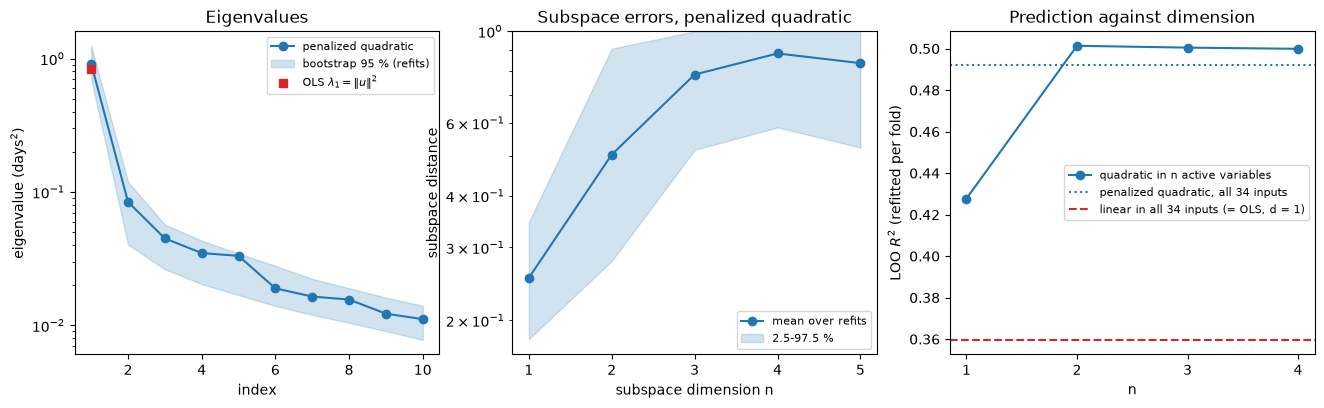

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
k = np.arange(1, 11)
ax = axes[0]
ax.semilogy(k, evq[:10], 'o-', c='C0', label='penalized quadratic')
ax.fill_between(k, np.percentile(boot_ev, 2.5, axis=0), np.percentile(boot_ev, 97.5, axis=0), color='C0',
                alpha=0.2, label='bootstrap 95 % (refits)')
ax.semilogy([1], [lam1], 's', c='C3', label=r'OLS $\lambda_1 = \|u\|^2$')
ax.set_xlabel('index')
ax.set_ylabel(r'eigenvalue (days$^2$)')
ax.set_title('Eigenvalues')
ax.legend(fontsize=8)
ax = axes[1]
ax.semilogy(np.arange(1, 6), boot_dist.mean(axis=0), 'o-', c='C0', label='mean over refits')
ax.fill_between(np.arange(1, 6), np.percentile(boot_dist, 2.5, axis=0), np.percentile(boot_dist, 97.5, axis=0),
                color='C0', alpha=0.2, label='2.5-97.5 %')
ax.set_ylim(top=1)
ax.set_xlabel('subspace dimension n')
ax.set_ylabel('subspace distance')
ax.set_title('Subspace errors, penalized quadratic')
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(NS, [LOO_N[n] for n in NS], 'o-', c='C0', label='quadratic in n active variables')
ax.axhline(loo_q, c='C0', ls=':', label='penalized quadratic, all 34 inputs')
ax.axhline(loo_lin, c='C3', ls='--', label='linear in all 34 inputs (= OLS, d = 1)')
ax.set_xticks(NS)
ax.set_xlabel('n')
ax.set_ylabel(r'LOO $R^2$ (refitted per fold)')
ax.set_title('Prediction against dimension')
ax.legend(fontsize=8)
plt.close(fig)
fig

Left: the penalized quadratic's eigenvalues with their bootstrap band, and the single OLS eigenvalue (0.8293
d², of the same size as the quadratic's $\lambda_1$ = 0.9144 d²). After $\lambda_1$ the spectrum falls by
10.88 and then decays slowly (0.0841, 0.0448, 0.0348, 0.0332 d²). Middle: the bootstrap subspace distance,
0.253 for $n = 1$ and 0.503 for $n = 2$. Right: the refitted LOO $R^2$ levels off at $n = 2$ (0.501).

#### Eigenvectors

Signs: $w_1$ so that $\tau$ increases along it (OLS's rule; the quadratic's $w_1$ is matched to it), $w_2$ with
its largest-magnitude entry positive. The paper shows no eigenvectors.

w1: k13 -0.579, k1 -0.355, emiss_vol -0.289, emiss_aer +0.289, emiss_terr +0.285, pOCSe_ant +0.214, r_aer -0.213, emiss_mar +0.161
w2: emiss_terr +0.403, emiss_mar +0.395, emiss_aer +0.333, k13 +0.301, k11 +0.276, r_aer -0.248, fk19 +0.186, acc_coeff +0.183
w2 entries whose bootstrap interval excludes 0: k11, k13, emiss_mar, emiss_terr, acc_coeff
OLS w1: k13 -0.529, k1 -0.361, emiss_terr +0.332, emiss_aer +0.318, emiss_vol -0.300, r_aer -0.202, emiss_mar +0.202, pOCSe_ant +0.189, k16 +0.173, k8 -0.161
OLS entries whose bootstrap 95 % interval excludes 0: 14 of 34
share of ||w1||^2: rate constants k1-k17 0.602; photolysis fk18-fk21 0.008; emission totals 0.192; speciation 0.054; acc_coeff 0.015; dummy aerosol (r, emiss, lat) 0.129
share of ||w2||^2: rate constants k1-k17 0.298; photolysis fk18-fk21 0.072; emission totals 0.343; speciation 0.080; acc_coeff 0.034; dummy aerosol (r, emiss, lat) 0.173


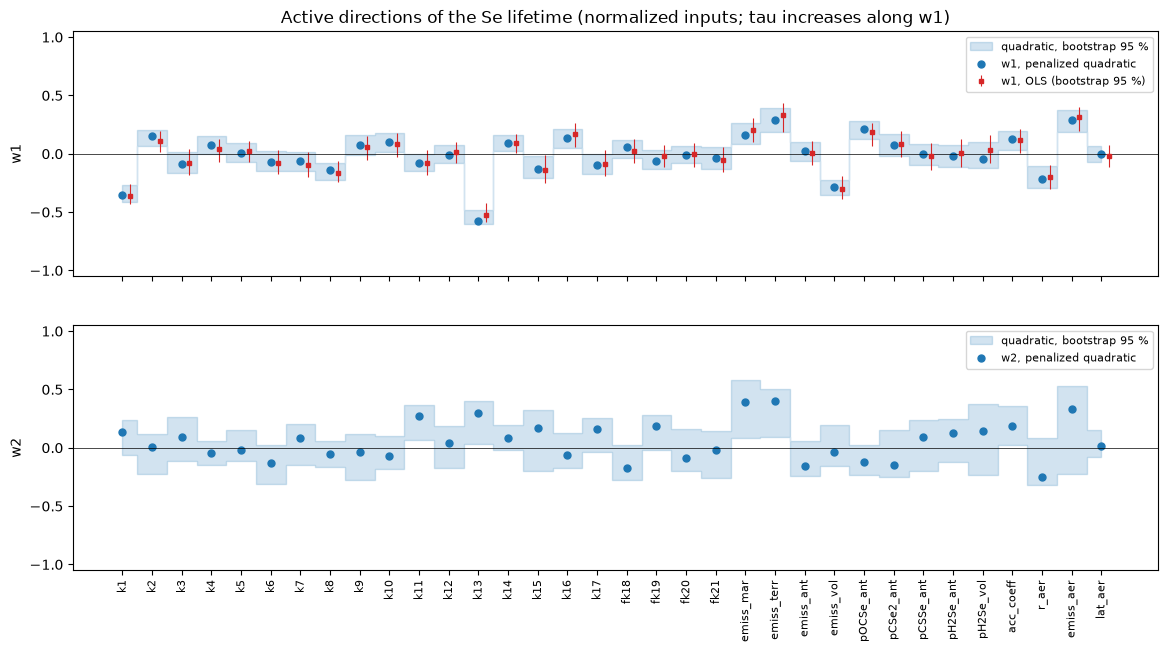

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
xs = np.arange(1, m + 1)
lo_b, hi_b = np.percentile(sub.bootstrap_eigenvectors[:, :, 0], [2.5, 97.5], axis=0)
for j, ax in enumerate(axes):
    blo, bhi = np.percentile(boot_W[:, :, j], [2.5, 97.5], axis=0)
    ax.fill_between(xs, blo, bhi, color='C0', alpha=0.2, step='mid', label='quadratic, bootstrap 95 %')
    ax.plot(xs, Wq[:, j], 'o', c='C0', ms=5, label=f'w{j + 1}, penalized quadratic')
    if j == 0:
        ax.errorbar(xs + 0.25, sub.W[:, 0], yerr=[sub.W[:, 0] - lo_b, hi_b - sub.W[:, 0]], fmt='s', c='C3', ms=3,
                    lw=0.8, label='w1, OLS (bootstrap 95 %)')
    ax.axhline(0, c='k', lw=0.5)
    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel(f'w{j + 1}')
    ax.legend(fontsize=8, loc='upper right')
axes[0].set_title('Active directions of the Se lifetime (normalized inputs; tau increases along w1)')
axes[1].set_xticks(xs)
axes[1].set_xticklabels(NAMES, rotation=90, fontsize=8)
plt.close(fig)
for j in range(2):
    wj = Wq[:, j]
    print(f'w{j + 1}: ' + ', '.join(f'{NAMES[i]} {wj[i]:+.3f}' for i in np.argsort(-np.abs(wj))[:8]))
blo, bhi = np.percentile(boot_W[:, :, 1], [2.5, 97.5], axis=0)
print('w2 entries whose bootstrap interval excludes 0: ' + ', '.join(NAMES[i] for i in range(m) if blo[i] > 0 or bhi[i] < 0))
w = sub.W[:, 0]
print('OLS w1: ' + ', '.join(f'{NAMES[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:10]))
print(f'OLS entries whose bootstrap 95 % interval excludes 0: {np.sum((lo_b > 0) | (hi_b < 0))} of {m}')
groups = {'rate constants k1-k17': range(17), 'photolysis fk18-fk21': range(17, 21),
          'emission totals': range(21, 25), 'speciation': range(25, 30), 'acc_coeff': [30],
          'dummy aerosol (r, emiss, lat)': [31, 32, 33]}
for j in range(2):
    print(f'share of ||w{j + 1}||^2: ' + '; '.join(f'{g} {np.sum(Wq[list(ix), j]**2):.3f}' for g, ix in groups.items()))
fig

$\tau$ increases along $w_1$ when $k_{13}$ (−0.579) and $k_1$ (−0.355), the rates of OCSe + OH and OCSe + O,
are slower, when volcanic emissions are smaller (−0.289), when the dummy aerosol emission is larger (+0.289) and
its radius smaller (−0.213), with more terrestrial (+0.285) and marine (+0.161) biogenic emissions and a larger
OCSe fraction of anthropogenic emissions (+0.214). The rate constants hold 0.602 of $\|w_1\|^2$, the emission
totals 0.192 and the dummy aerosol 0.129. OLS gives the same entries (k13 −0.529, k1 −0.361, emiss_terr
+0.332, emiss_aer +0.318, emiss_vol −0.300), 14 of 34 with a bootstrap interval that excludes zero. $w_2$ is led
by the biogenic emissions (emiss_terr +0.403, emiss_mar +0.395), the dummy aerosol emission (+0.333), $k_{13}$
(+0.301) and $k_{11}$ (+0.276); only k11, k13, emiss_mar, emiss_terr and acc_coeff have bootstrap intervals that
exclude zero. The photolysis factors and the latitude band barely enter $\mathbf w_1$. For lat_aer this
says only that the quadratic, in which the band enters through its coded midpoint, finds no linear or symmetric
effect of it; a non-monotone effect of the band cannot appear in these directions (see below).

#### Sufficient summary plots

k13 < 1e-12: 231 runs, mean tau 4.66 d, Spearman rho(log10 k13, tau) -0.30
k13 >= 1e-12: 169 runs, mean tau 4.23 d, Spearman rho(log10 k13, tau) -0.11
residual of the quadratic in y1: Spearman rho with y2 +0.24; the run with the largest tau (10.07 d) has y1 = +1.35, y2 = -2.51
Spearman rho(y2, log10(emiss_aer / r_aer)) = +0.31; rho(y1, same) = +0.30
quadratic in y1: minimum at y1 = -0.79; 33 runs lie left of it (mean tau 3.95 d, against 4.12 d for the 159 runs in an equally wide window to its right)
Kruskal-Wallis by latitude band: tau p = 0.33; residual of the quadratic in (y1, y2) p = 0.005
  band means hold 0.086 of the residual sum of squares (about 0.043 expected with no band effect)
  band means of the residual (d): 1: -0.09, 2: -0.14, 3: -0.07, 4: +0.06, 5: -0.26, 6: +0.02, 7: +0.06, 8: +0.31, 9: +0.04, 10: +0.03, 11: -0.04, 12: +0.08, 13: +0.07, 14: +0.16, 15: -0.09, 16: -0.01, 17: -0.03, 18: -0.11


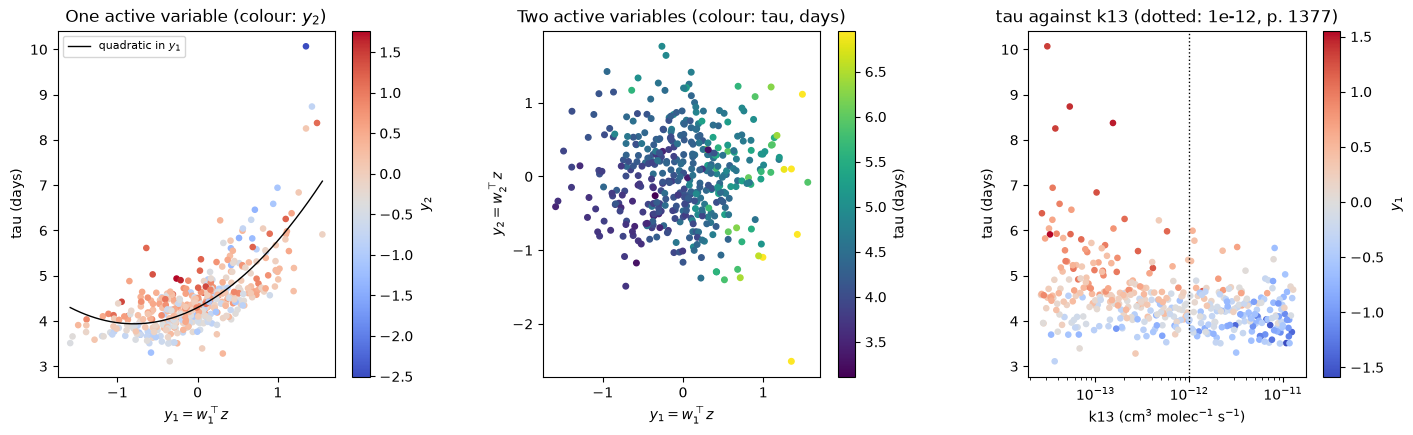

In [17]:
Y = Z @ Wq[:, :2]
c2, *_ = np.linalg.lstsq(poly2(Y[:, :1]), tau, rcond=None)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ax = axes[0]
sc = ax.scatter(Y[:, 0], tau, c=Y[:, 1], cmap='coolwarm', s=14)
yy = np.linspace(Y[:, 0].min(), Y[:, 0].max(), 200)
ax.plot(yy, poly2(yy[:, None]) @ c2, 'k-', lw=1, label='quadratic in $y_1$')
ax.set_xlabel(r'$y_1 = w_1^\top z$')
ax.set_ylabel('tau (days)')
ax.set_title('One active variable (colour: $y_2$)')
fig.colorbar(sc, ax=ax, label='$y_2$')
ax.legend(fontsize=8)
ax = axes[1]
sc = ax.scatter(Y[:, 0], Y[:, 1], c=tau, cmap='viridis', s=16, vmax=np.percentile(tau, 99))
ax.set_xlabel(r'$y_1 = w_1^\top z$')
ax.set_ylabel(r'$y_2 = w_2^\top z$')
ax.set_title('Two active variables (colour: tau, days)')
fig.colorbar(sc, ax=ax, label='tau (days)')
ax = axes[2]
k13 = X[:, NAMES.index('k13')]
sc = ax.scatter(k13, tau, c=Y[:, 0], cmap='coolwarm', s=14)
ax.set_xscale('log')
ax.axvline(1e-12, c='k', ls=':', lw=1)
ax.set_xlabel('k13 (cm$^3$ molec$^{-1}$ s$^{-1}$)')
ax.set_ylabel('tau (days)')
ax.set_title('tau against k13 (dotted: 1e-12, p. 1377)')
fig.colorbar(sc, ax=ax, label='$y_1$')
fig.subplots_adjust(wspace=0.4)
plt.close(fig)
lowk = k13 < 1e-12
for name, sel in (('k13 < 1e-12', lowk), ('k13 >= 1e-12', ~lowk)):
    rho = stats.spearmanr(np.log10(k13[sel]), tau[sel])[0]
    print(f'{name}: {sel.sum()} runs, mean tau {tau[sel].mean():.2f} d, Spearman rho(log10 k13, tau) {rho:+.2f}')
area_proxy = np.log10(X[:, ie] / X[:, ir])                  # emitted mass / radius, as in the paper's Fig. 7c
res_y1 = tau - poly2(Y[:, :1]) @ c2
print(f'residual of the quadratic in y1: Spearman rho with y2 {stats.spearmanr(Y[:, 1], res_y1)[0]:+.2f}; '
      f'the run with the largest tau ({tau.max():.2f} d) has y1 = {Y[np.argmax(tau), 0]:+.2f}, y2 = {Y[np.argmax(tau), 1]:+.2f}')
print(f'Spearman rho(y2, log10(emiss_aer / r_aer)) = {stats.spearmanr(Y[:, 1], area_proxy)[0]:+.2f}; '
      f'rho(y1, same) = {stats.spearmanr(Y[:, 0], area_proxy)[0]:+.2f}')
y_v = -c2[1] / (2 * c2[2])                                   # vertex of the quadratic in y1 (left panel)
left = Y[:, 0] < y_v
nxt = (Y[:, 0] >= y_v) & (Y[:, 0] < y_v + (y_v - Y[:, 0].min()))
print(f'quadratic in y1: minimum at y1 = {y_v:+.2f}; {left.sum()} runs lie left of it (mean tau {tau[left].mean():.2f} d, '
      f'against {tau[nxt].mean():.2f} d for the {nxt.sum()} runs in an equally wide window to its right)')
# lat_aer is discrete: a quadratic in z can show only a linear or symmetric effect of the band. Test the
# residuals of the quadratic in (y1, y2) for an effect of the band.
band = X[:, il].astype(int)
c22, *_ = np.linalg.lstsq(poly2(Y), tau, rcond=None)
res2 = tau - poly2(Y) @ c22
bm = np.array([res2[band == b].mean() for b in range(1, 19)])
share = np.sum([np.sum(band == b) * bm[b - 1]**2 for b in range(1, 19)]) / np.sum((res2 - res2.mean())**2)
print(f'Kruskal-Wallis by latitude band: tau p = {stats.kruskal(*[tau[band == b] for b in range(1, 19)]).pvalue:.2f}; '
      f'residual of the quadratic in (y1, y2) p = {stats.kruskal(*[res2[band == b] for b in range(1, 19)]).pvalue:.3f}')
print(f'  band means hold {share:.3f} of the residual sum of squares (about {17 / (M - 1):.3f} expected with no band effect)')
print('  band means of the residual (d): ' + ', '.join(f'{b}: {v:+.2f}' for b, v in zip(range(1, 19), bm)))
fig

In one active variable (left) $\tau$ rises along $y_1$ with growing scatter, and the longest lifetimes sit at the
right end. In two (middle) $\tau$ grows mainly along $y_1$, and at a given $y_1$ runs with larger $y_2$ lie
above the one-variable quadratic (Spearman correlation of its residual with $y_2$: +0.24); the run with the
largest $\tau$ (10.07 d, at $y_1$ = +1.35) is an exception, at $y_2$ = −2.51. Right: $\tau$ against $k_{13}$
itself. For $k_{13}$ < 1e-12 (231 runs) $\tau$ falls with $k_{13}$ (Spearman −0.30, mean 4.66 d); above it
(169 runs) hardly (−0.11, mean 4.23 d), the saturation the paper describes (p. 1377). A quadratic in $y_1$ cannot follow such a kink in one input, which is
one reason a second variable helps. $y_2$ correlates with $\log_{10}$(emiss_aer / r_aer), the paper's proxy for
the emitted dummy-aerosol surface area (Fig. 7c), with Spearman +0.31 ($y_1$: +0.30).

The upturn of the quadratic in $y_1$ to the left of its minimum ($y_1$ = −0.79) is an artifact of the
polynomial form, not of the data: the 33 runs there have a lower mean $\tau$ (3.95 d) than the 159 runs in an
equally wide window to its right (4.12 d). The latitude band of the dummy aerosol has no detectable effect on
$\tau$ alone (Kruskal–Wallis p = 0.33), but the residuals of the quadratic in $(y_1, y_2)$ differ by band
(p = 0.005): the band means hold 0.086 of the residual sum of squares, against about 0.043 expected with no
effect, in a non-monotone pattern (band 5 −0.26 d, band 8 +0.31 d, band 14 +0.16 d). A quadratic in the coded
band can represent only a linear or symmetric effect, so this part of $\tau$ lies outside the subspace found
here.

### The validation runs

The paper ran 50 validation runs to test its surrogates (p. 1374). Their inputs were chosen "by enriching the
training experimental design to create a pseudo-Latin hypercube of 450 runs, ensuring that the distance between
the validation runs and existing training runs is maximal" (p. 1374), so they are not an independent draw from
the input law. Their input values were not offered with the deposited data, so they cannot test this
notebook's fits point by point; the cell compares distributions.

In [18]:
print(f'validation runs (no inputs): tau 2/50/98 % = ' + ' / '.join(f'{v:.2f}' for v in np.percentile(tau_v, pct))
      + f' d; KS against the training runs p = {ks.pvalue:.2f}')
print(f'LOO predictions of the 2-D quadratic: 2/50/98 % = ' + ' / '.join(f'{v:.2f}' for v in np.percentile(pred[2], pct))
      + f' d (the observed training tau: ' + ' / '.join(f'{v:.2f}' for v in np.percentile(tau, pct)) + ')')
order = np.argsort(-np.abs(Wq[:, 0]))
print('rank in |w1| (quadratic): ' + ', '.join(f'{NAMES[i]} {k + 1}' for k, i in enumerate(order[:10])))
dummy = [ir, ie, il]
print(f'share of ||w1||^2 and ||w2||^2 on the dummy aerosol inputs: {np.sum(Wq[dummy, 0]**2):.3f}, '
      f'{np.sum(Wq[dummy, 1]**2):.3f}')
print(f'1 - LOO R^2: penalized quadratic {1 - loo_q:.3f}, two active variables {1 - LOO_N[2]:.3f}, linear {1 - loo_lin:.3f}')
print(f'run time {time.perf_counter() - t_start:.0f} s')

validation runs (no inputs): tau 2/50/98 % = 3.52 / 4.28 / 6.42 d; KS against the training runs p = 0.46
LOO predictions of the 2-D quadratic: 2/50/98 % = 3.70 / 4.35 / 5.89 d (the observed training tau: 3.52 / 4.36 / 6.38)
rank in |w1| (quadratic): k13 1, k1 2, emiss_vol 3, emiss_aer 4, emiss_terr 5, pOCSe_ant 6, r_aer 7, emiss_mar 8, k2 9, k8 10
share of ||w1||^2 and ||w2||^2 on the dummy aerosol inputs: 0.129, 0.173
1 - LOO R^2: penalized quadratic 0.508, two active variables 0.499, linear 0.640
run time 46 s


The distribution of $\tau$ over the validation runs is close to that of the training runs (2/50/98 %:
3.52 / 4.28 / 6.42 d). The KS test (p = 0.46) only fails to reject equality, and the validation design is a
distance-maximizing enrichment, not an independent sample, so this is a consistency check. The leave-one-out predictions of the two-variable quadratic have the right median (4.35
against 4.36 d) but a compressed range (3.70–5.89 against 3.52–6.38 d), as expected of a fit with LOO $R^2$
0.501.

**Ranking against Fig. 5.** What agrees: $k_{13}$ is first in $|w_1|$ and has the largest total Sobol' index
(Fig. 5, p. 1378); the dummy aerosol (emiss_aer fourth, r_aer seventh) and emiss_vol (third) are near the top
of both rankings; and the signs of $w_1$ match the effects described in Sect. 5.1 (next section). The order
after $k_{13}$ differs: $k_1$ is second here and fifth in Fig. 5, emiss_mar eighth here and fourth there,
emiss_terr fifth here and ninth there, and %H2Se_vol and $k_{15}$ are not among the first ten entries of $|w_1|$.
The two rankings measure different things. A total Sobol' index counts every interaction of an input; an entry
of $w_1$ measures the input's share of the dominant gradient direction, which here is close to the linear trend
($|w_1^\top \hat w_1|$ = 0.986). Inputs whose total index is mostly interaction, as for emiss_mar, $k_{15}$ and
%H2Se_vol, whose Fig. 5 bars are mostly the interaction part (the paper: $k_{15}$ and the H2Se fraction act
"mainly through interaction terms", p. 1378), need not rank high in $w_1$.

## Comparison with the paper

The paper reports no active subspace. Sobol' indices in Fig. 5 (p. 1378) are printed only as bars; the values
below were read off the bars (about ±0.01).

| quantity | paper (page) | notebook |
|---|---|---|
| median of $\tau$ | 4.4 d (Fig. 4, p. 1377; abstract, p. 1363) | 4.36 d over the 400 runs (bootstrap [4.30, 4.42]); validation runs 4.28 d |
| 2nd percentile of $\tau$ | 2.9 d (Fig. 4) | **3.52 d** ([3.50, 3.63]); minimum of the runs 3.11 d |
| 98th percentile of $\tau$ | 6.4 d (Fig. 4) | 6.38 d ([5.98, 6.97]) |
| deposition / emission | 98–102 % in all 400 runs (p. 1376) | 0.988–1.233 with the deposited emiss_vol; 0.987–1.023 with a volcanic factor 1.269 |
| volcanic emission range | 0.076–49.1 Gg Se/yr (Table 3, p. 1370) | design column a Latin hypercube on [0.06, 39] (column units); on Table 3's range 293 of 400 strata and 15 runs below; candidate cause (this data set's inference): Se/S ratios (p. 1371) × 10 instead of 12.6 Tg S/yr; see Mass balance |
| wet share of deposition | "around 80 %" (abstract, p. 1363; literature estimate, p. 1376) | median 0.771 (0.696–0.889) |
| error of the lifetime surrogate | 0.35 (ratio of two PCEs, p. 1376) | 1 − LOO $R^2$: 0.508 (penalized quadratic), 0.499 (two active variables), 0.640 (linear) |
| first-order Sobol' indices | sum 53 % of the variance (p. 1377) | in-sample $R^2$ of the linear fit 0.470 (for the input law, the variance of the best linear part cannot exceed the first-order sum) |
| most important input | $k_{13}$, total index ≈ 0.31 (Fig. 5) | $k_{13}$, first in $w_1$ (−0.579) and in OLS (−0.529) |
| next inputs | dummy aerosol ≈ 0.28, emiss_vol ≈ 0.17, emiss_mar ≈ 0.15, $k_1$ ≈ 0.13; then %H2Se_vol, %OCSe_ant, $k_{15}$, emiss_terr ≈ 0.05–0.07 (Fig. 5) | $\lvert w_1\rvert$ order: k13, k1, emiss_vol, emiss_aer, emiss_terr, pOCSe_ant, r_aer, emiss_mar; $k_{13}$ first and the dummy aerosol and emiss_vol near the top agree, the order after $k_{13}$ differs (see The validation runs) |
| directions of the effects | slower $k_{13}$, $k_1$, more OCSe in anthropogenic emissions, less volcanic and more biogenic emission lengthen $\tau$ (pp. 1377–1378) | the same signs in $w_1$ |
| $k_{13}$ saturation | influence "mostly saturated above $10^{-12}$" (p. 1377) | Spearman −0.30 below 1e-12, −0.11 above |
| dummy aerosol | $\tau$ grows with emitted surface area ∝ emission / radius (Fig. 7c, p. 1378) | emiss_aer + and r_aer − in $w_1$; $y_2$ vs log(emiss/r) Spearman +0.31 |
| interactions | $k_1 \times k_{13}$ 5.3 %, r_aer × emiss_aer 5.0 % of variance (p. 1377) | not computed |
| active subspace, dimension | not reported | $n = 2$ (LOO $R^2$ 0.428 → 0.501 → 0.500; the same step for $1/\tau$ and $\log\tau$); $\lambda_1/\lambda_2$ = 10.88 at the chosen penalty (6.03–38.56 over penalties within 0.05 of the best LOO $R^2$), $\lambda_2/\lambda_3$ = 1.88 |
| deposition over agricultural land | mean Sobol' indices over cropland and pasture (Fig. 11, p. 1383; maps of Ramankutty et al. 2008) | not reported as a value in the paper; not computed (the maps are not in the deposit) |

The surrogate error of the paper (0.35) and the notebook's 1 − LOO $R^2$ are not the same measure (the paper
does not define its value further), and the notebook's fits are polynomials of degree 2, not sparse PCEs of
degree up to 13.

## References

- A. Feinberg, M. Maliki, A. Stenke, B. Sudret, T. Peter, L. H. E. Winkel. Mapping the drivers of uncertainty in
  atmospheric selenium deposition with global sensitivity analysis. *Atmospheric Chemistry and Physics*
  20(3):1363–1390, 2020. [doi:10.5194/acp-20-1363-2020](https://doi.org/10.5194/acp-20-1363-2020)
- A. Feinberg, M. Moustapha, A. Stenke, B. Sudret, T. Peter, L. H. E. Winkel. Simulation data used for
  sensitivity analysis of atmospheric selenium in SOCOL-AER. ETH Research Collection, 2019.
  [doi:10.3929/ethz-b-000357105](https://doi.org/10.3929/ethz-b-000357105) (authors as listed by the record and
  by the paper's reference list, Feinberg et al. 2019a; the paper's second author is Moustapha Maliki)
- J.-X. Sheng, D. K. Weisenstein, B.-P. Luo, E. Rozanov, A. Stenke, J. Anet, H. Bingemer, T. Peter. Global
  atmospheric sulfur budget under volcanically quiescent conditions: Aerosol-chemistry-climate model
  predictions and validation. *Journal of Geophysical Research: Atmospheres* 120(1):256–276, 2015.
  [doi:10.1002/2014JD021985](https://doi.org/10.1002/2014JD021985)
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
- K.-C. Li. Sliced inverse regression for dimension reduction. *Journal of the American Statistical
  Association* 86(414):316–327, 1991. [doi:10.1080/01621459.1991.10475035](https://doi.org/10.1080/01621459.1991.10475035)

## Acknowledgments

The paper's research was supported by ETH Zurich (grant no. ETH-39 15-2). The data are © the authors, CC BY 4.0.